In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("/Users/jasleenkaur/markovate-assessment/data/raw/bank.csv")

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [5]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no
11161,34,technician,married,secondary,no,0,no,no,cellular,9,jul,628,1,-1,0,unknown,no


In [6]:
df.shape

(11162, 17)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [8]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [9]:
df.describe(include = "object")

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,11162,11162,11162,11162,11162,11162,11162,11162,11162,11162
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2566,6351,5476,10994,5881,9702,8042,2824,8326,5873


In [10]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

In [11]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.nunique()

age            76
job            12
marital         3
education       4
default         2
balance      3805
housing         2
loan            2
contact         3
day            31
month          12
duration     1428
campaign       36
pdays         472
previous       34
poutcome        4
deposit         2
dtype: int64

In [15]:
df["deposit"].value_counts()

deposit
no     5873
yes    5289
Name: count, dtype: int64

In [18]:
categorical_columns = df.select_dtypes(include = "object").columns

for col in categorical_columns:
    unknown_counts =(df[col] == "unknown").sum()
    if unknown_counts > 0:
        print(f"{col}: {unknown_counts} unknown values")

job: 70 unknown values
education: 497 unknown values
contact: 2346 unknown values
poutcome: 8326 unknown values


In [19]:
for col in categorical_columns:
    unknown_counts = (df[col] == "unknown").sum()
    if unknown_counts > 0:
        unknown_percentage = (unknown_counts/len(df)) * 100
        print(f"{col}: {unknown_percentage:.2f}% unknown") 

job: 0.63% unknown
education: 4.45% unknown
contact: 21.02% unknown
poutcome: 74.59% unknown


In [20]:
numeric_columns = df.select_dtypes(include = "number").columns

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]
    print(f"{col}: {len(outliers)} potential outliers")

age: 171 potential outliers
balance: 1055 potential outliers
day: 0 potential outliers
duration: 636 potential outliers
campaign: 601 potential outliers
pdays: 2750 potential outliers
previous: 1258 potential outliers


In [22]:
import matplotlib.pyplot as plt

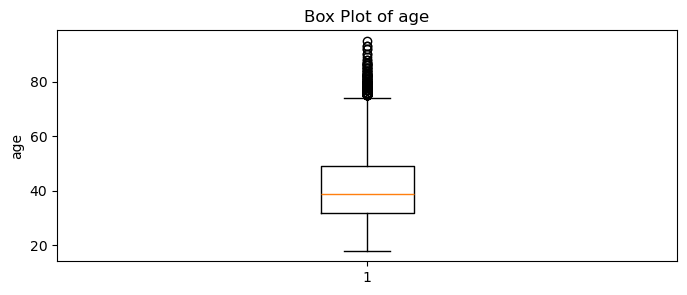

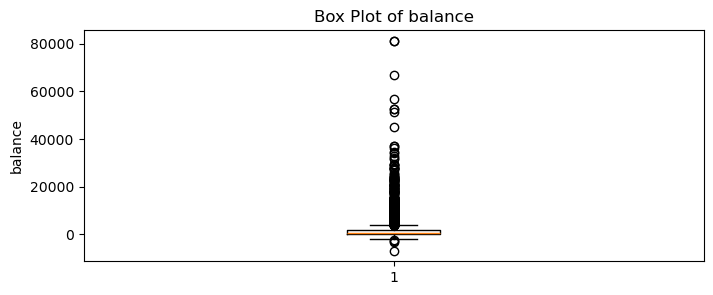

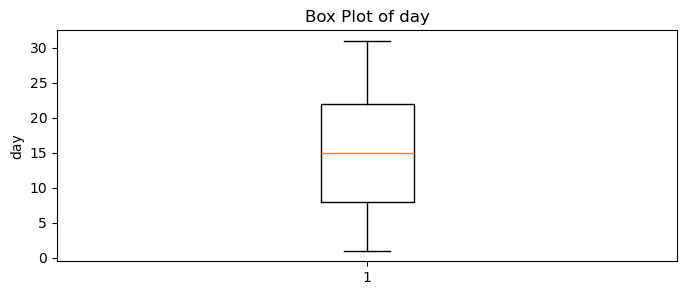

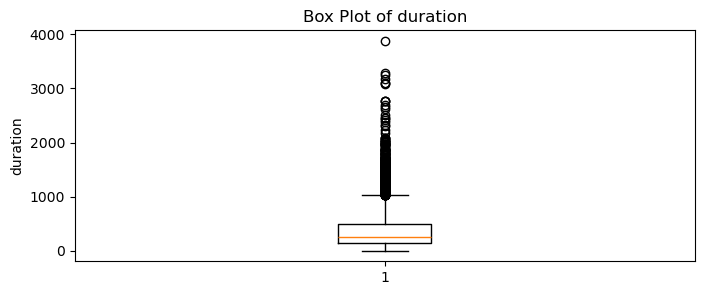

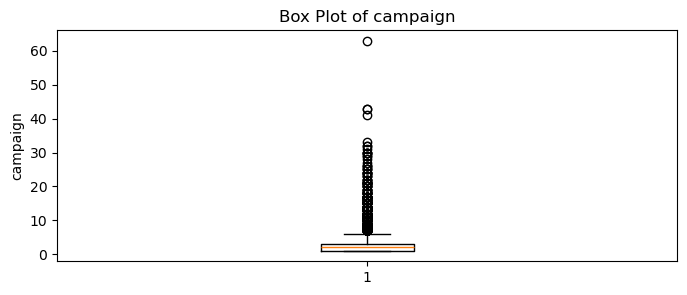

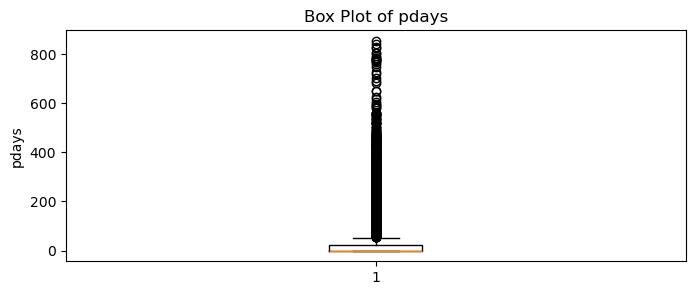

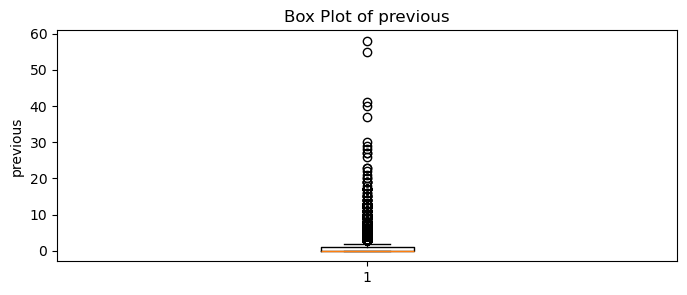

In [24]:
for col in numeric_columns:
    plt.figure(figsize = (8,3))
    plt.boxplot(df[col])
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.show()

In [25]:
df["deposit"].value_counts(normalize = True) * 100

deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64

In [27]:
categorical_columns = df.select_dtypes(include = "object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


job:
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64

marital:
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64

education:
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64

default:
default
no     10994
yes      168
Name: count, dtype: int64

housing:
housing
no     5881
yes    5281
Name: count, dtype: int64

loan:
loan
no     9702
yes    1460
Name: count, dtype: int64

contact:
contact
cellular     8042
unknown      2346
telephone     774
Name: count, dtype: int64

month:
month
may    2824
aug    1519
jul    1514
jun    1222
nov     943
apr     923
feb     776
oct     392
jan     344
sep     319
mar     276
dec     110
Name: count, dtype: int64

po